# Model A: SARIMAX M1–M4

팀 공통 입력 조건 M1–M4(`feature_sets.json`의 `model_B_M1`–`M4`와 같은 관측소)로 SARIMAX를 적합하고 2023 검증으로 채점합니다. 관측소 묶음마다 시간별 평균 1개를 외생변수로 넣습니다.

## 1. 작업 폴더

In [1]:
import os, sys, zipfile
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/TSA_planA')
except ImportError:
    BASE = Path.cwd()
print(sorted(p.name for p in BASE.iterdir()))

['ModelA_SARIMAX_M1_M4_colab.ipynb', 'PlanA_data.zip']


## 2. 데이터

In [2]:
if not (BASE / 'TSA' / 'Dataset').exists():
    target = ('\\\\?\\' + str(BASE)) if os.name == 'nt' else str(BASE)
    with zipfile.ZipFile(BASE / 'PlanA_data.zip') as z:
        z.extractall(target)
os.environ['TSA_ROOT'] = str(BASE / 'TSA')
(BASE / 'planA_M').mkdir(exist_ok=True)
os.chdir(BASE / 'planA_M')
Path('figures_en').mkdir(exist_ok=True)
print(sorted(p.name for p in (BASE / 'TSA' / 'Dataset').iterdir()))

import subprocess
def run(*args):
    p = subprocess.Popen([sys.executable, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    for line in p.stdout:
        print(line, end='')
    if p.wait() != 0:
        raise RuntimeError(f'{args[0]} failed')

['China', 'China_Border_Proxy', 'Evaluation_Contract_20261107', 'Japan', 'Korea_Air', 'Korea_East_Candidates', 'Mongolia', 'Origin_Features_2021_2024_v3', 'PLAN_A_BUNDLE.txt', 'Trajectory_Matching_2021_2024_v3']


## 3. 코드

In [3]:
%%writefile config.py
"""Shared paths and fixed settings for models A-D. Every model reads from here."""
from pathlib import Path

import os
# Plan A: data from Dataset_11_07_regions_v5.zip. Set TSA_ROOT on Colab (e.g. /content/drive/MyDrive/TSA).
ROOT = Path(os.environ.get("TSA_ROOT", Path(__file__).resolve().parents[1] / "TSA"))
if os.name == "nt" and not str(ROOT).startswith("\\\\?\\"):
    ROOT = Path("\\\\?\\" + str(ROOT))                 # Windows long-path prefix (paths > 260 chars)
DATASET = ROOT / "Dataset"
FEATURES = DATASET / "Origin_Features_2021_2024_v3"
MATCHING = DATASET / "Trajectory_Matching_2021_2024_v3"
FEATURE_CODE = DATASET / "Codes" / "Origin_Features_v3"
MODELS = Path(__file__).resolve().parent
WORK = MODELS / "work"                 # derived inputs (region means, node matrix, graphs)
PRED = MODELS / "predictions"          # one parquet per model, common schema
RESULTS = MODELS / "results"           # scores, coefficient tables, importance, weights

HORIZONS = (3, 6, 12, 24)              # 6 h primary
SPLITS = ("train", "validation", "test")
TARGET_KEY = "KR:111121"               # Seoul Jung-gu
SEOUL = (126.98, 37.57)                # lon, lat (team receptor)
SEEDS = (0, 1, 2)
HIGH_PM = 35.0                         # ug/m3, high-concentration threshold


def split_of(year):
    return "train" if year <= 2022 else "validation" if year == 2023 else "test"


for d in (WORK, PRED, RESULTS):
    d.mkdir(exist_ok=True)


Writing config.py


In [4]:
%%writefile data_access.py
"""Hourly source readers shared by the region table, node matrix and SARIMA (no imputation)."""
import numpy as np
import pandas as pd

from config import DATASET, MATCHING, TARGET_KEY

SOURCES = {  # dataset -> (country, main file, buffer file)
    "Korea_Air": ("KR", "korea_34stations_hourly_2021_2024_kst.parquet", "korea_context_buffer.parquet"),
    "Korea_East_Candidates": ("KR", "korea_east_36stations_hourly_2021_2024_kst.parquet", "korea_east_context_buffer.parquet"),
    "China": ("CN", "china_48stations_hourly_2021_2024_kst.parquet", "china_48stations_context_buffer.parquet"),
    "Japan": ("JP", "japan_west_hourly_2021_2024_kst.parquet", "japan_west_context_buffer.parquet"),
    "Mongolia": ("MN", "mongolia_ub_embassy_hourly_2021_2024_kst.parquet", "mongolia_ub_embassy_context_buffer.parquet"),
    "China_Border_Proxy": ("CN", "china_border_cities_hourly_2021_2024_kst.parquet", "china_border_cities_context_buffer.parquet"),
}
HOUR_INDEX = pd.date_range("2020-12-29 00:00", "2025-01-01 00:00", freq="h", tz="Asia/Seoul")


def registry():
    """v3 matching registry (317 external candidates) plus the Seoul target, as a DataFrame."""
    r = pd.read_csv(MATCHING / "station_registry.csv", dtype=str, encoding="utf-8-sig")
    r[["longitude", "latitude"]] = r[["longitude", "latitude"]].astype(float)
    return r


def hourly_pm25(keys):
    """Wide hourly PM2.5 table (HOUR_INDEX x station_key); flag != 0 stays NaN."""
    want = set(keys)
    cols = {}
    for ds, (cc, main, buf) in SOURCES.items():
        ids = sorted(k.split(":", 1)[1] for k in want if k.startswith(cc + ":"))
        if not ids:
            continue
        for f in (main, buf):
            t = pd.read_parquet(DATASET / ds / f, columns=["time_kst", "station_id", "pm25"],
                                filters=[("station_id", "in", ids)])
            for sid, g in t.groupby("station_id"):
                key = f"{cc}:{sid}"
                if key in want:
                    s = g.set_index("time_kst").pm25
                    cols.setdefault(key, []).append(s)
    out = pd.DataFrame({k: pd.concat(v).sort_index() for k, v in cols.items()}).reindex(HOUR_INDEX)
    missing = want - set(out.columns)
    assert not missing, f"no source rows for {sorted(missing)[:5]}"
    return out[list(keys)]


def seoul_pm25():
    return hourly_pm25([TARGET_KEY])[TARGET_KEY]


def asos_hourly():
    """ASOS 108/102 hourly temperature, humidity, pressure, wind u/v (team rule: calm -> 0, dir 0 -> NaN)."""
    parts = []
    for f in ("asos_102_108_hourly_2021_2024_kst.parquet", "asos_context_after.parquet"):
        parts.append(pd.read_parquet(DATASET / "ASOS" / f))
    a = pd.concat(parts)
    out = {}
    for st in ("108", "102"):
        g = a[a.station_id == st].set_index("time_kst").sort_index()
        spd, dr = g.wind_speed, g.wind_direction
        good = spd.gt(0) & dr.gt(0) & dr.le(360)
        u = (-spd * np.sin(np.deg2rad(dr))).where(good)
        v = (-spd * np.cos(np.deg2rad(dr))).where(good)
        u, v = u.mask(spd.eq(0), 0.0), v.mask(spd.eq(0), 0.0)
        for name, s in (("temperature", g.temperature), ("rh", g.relative_humidity),
                        ("pressure", g.surface_pressure), ("wind_u", u), ("wind_v", v)):
            out[f"asos{st}_{name}"] = s
    return pd.DataFrame(out).reindex(HOUR_INDEX)


Writing data_access.py


In [5]:
%%writefile grid.py
"""Common evaluation grid: 3-hourly origins t, targets y(t+h), eligibility and condition labels.

Everything comes from Origin_Features_v3 metadata, so all models are scored on the same rows.
"""
import numpy as np
import pandas as pd

from config import FEATURES, HORIZONS

COLD_MONTHS = (11, 12, 1, 2, 3)
SECTOR_GROUP = {"NW": "west", "W": "west", "SW": "west", "N": "north", "NE": "north",
                "E": "east", "SE": "east", "S": "east", "LOCAL": "local"}


def load_grid():
    """One row per origin: time, split, y_pm25_h*, eligible_h*, persistence input and condition labels."""
    cols = (["origin_time_kst", "origin_split", "route_history12h_sector", "seoul_pm25_now",
             "asos108_wind_u_now", "asos108_wind_v_now", "asos108_wind_calm_now",
             "met_b01_06_u_mean", "met_b01_06_v_mean"]
            + [f"y_pm25_h{h}" for h in HORIZONS] + [f"eligible_h{h}" for h in HORIZONS])
    g = pd.read_parquet(FEATURES / "origin_features_2021_2024_kst.parquet", columns=cols)
    g["season"] = np.where(g.origin_time_kst.dt.month.isin(COLD_MONTHS), "cold", "warm")
    g["route_group"] = g.route_history12h_sector.map(SECTOR_GROUP)
    g["wind_sector"] = wind_sector(g.asos108_wind_u_now, g.asos108_wind_v_now, g.asos108_wind_calm_now)
    # wind at trajectory level (~500 m AGL, about 950 hPa) over the last 6 h of the arriving path; the data have no
    # 850 hPa field, so this is the closest available upper-air wind. Below 0.5 m/s counts as calm.
    u, v = g.met_b01_06_u_mean, g.met_b01_06_v_mean
    g["traj_wind_sector"] = wind_sector(u, v, (np.hypot(u, v) < 0.5).astype(int))
    return g


def wind_sector(u, v, calm):
    """Direction the wind blows FROM (4 sectors) from ASOS u/v at t; 'calm' or 'unknown' otherwise."""
    frm = (np.degrees(np.arctan2(-u, -v)) + 360) % 360
    sec = np.select([(frm >= 225) & (frm < 315), (frm >= 315) | (frm < 45), (frm >= 45) & (frm < 135)],
                    ["west", "north", "east"], "south")
    out = pd.Series(sec, index=u.index).where(u.notna() & v.notna(), "unknown")
    return out.where(calm.ne(1), "calm")


def long_targets(g, split=None):
    """(origin, horizon) rows with y and eligibility; optionally one split."""
    parts = []
    for h in HORIZONS:
        p = g[["origin_time_kst", "origin_split", "season", "route_group", "wind_sector", "traj_wind_sector"]].copy()
        p["horizon"], p["y"], p["eligible"] = h, g[f"y_pm25_h{h}"], g[f"eligible_h{h}"]
        parts.append(p)
    out = pd.concat(parts, ignore_index=True)
    out = out[out.eligible]
    return out if split is None else out[out.origin_split == split]


Writing grid.py


In [6]:
%%writefile predictions_io.py
"""The one prediction format every model writes: origin_time_kst, horizon, model, split, y_hat (ug/m3).

Each <model>.parquet gets a sidecar <model>.meta.json: data version (feature manifest version/created time),
seeds and the settings the model passes in, so every prediction can be traced to its inputs.
"""
import json
from datetime import datetime, timedelta, timezone

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from config import FEATURES, HORIZONS, PRED, SPLITS

SCHEMA = pa.schema([("origin_time_kst", pa.timestamp("us", tz="Asia/Seoul")), ("horizon", pa.int8()),
                    ("model", pa.string()), ("split", pa.string()), ("y_hat", pa.float64())])


def data_version():
    m = json.loads((FEATURES / "feature_manifest.json").read_text(encoding="utf-8"))
    return {"features_version": m["version"], "features_created_kst": m["created_kst"],
            "features_rows": m["rows"], "features_columns": m["columns"]}


def save(df, model, meta=None):
    """Validate and write predictions/<model>.parquet (+ .meta.json); overwrites only that model's own files."""
    (PRED / f"{model}.meta.json").write_text(json.dumps(
        {"model": model, "written_kst": datetime.now(timezone(timedelta(hours=9))).isoformat(timespec="seconds"),
         **data_version(), **(meta or {})}, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
    df = df.assign(model=model)[SCHEMA.names]
    assert set(df.horizon.unique()) <= set(HORIZONS) and set(df.split.unique()) <= set(SPLITS)
    assert not df.duplicated(["origin_time_kst", "horizon"]).any(), "duplicate origin/horizon"
    df = df.assign(origin_time_kst=pd.to_datetime(df.origin_time_kst).dt.tz_convert("Asia/Seoul"))
    pq.write_table(pa.Table.from_pandas(df, schema=SCHEMA, preserve_index=False), PRED / f"{model}.parquet")
    return PRED / f"{model}.parquet"


def load(models):
    return pd.concat([pd.read_parquet(PRED / f"{m}.parquet") for m in models], ignore_index=True)


def wide_to_long(origins, splits, preds, model, meta=None):
    """preds: {h: array aligned with origins} -> long frame."""
    rows = [pd.DataFrame({"origin_time_kst": origins, "horizon": h, "split": splits, "y_hat": v})
            for h, v in preds.items()]
    return save(pd.concat(rows, ignore_index=True), model, meta)


Writing predictions_io.py


In [7]:
%%writefile a_sarimax.py
"""A: SARIMA (Seoul only) and SARIMAX (lagged regional means) on hourly log1p PM2.5.

- Fit once on 2021-2022; parameters fixed; the Kalman filter is run through 2023-2024 and the filtered state
  a_{t|t} is pushed h steps with the transition matrix (method from the earlier project's tested sarimax_fc).
- Seasonality: deterministic daily and annual Fourier terms (2 harmonics each) -- known in advance, no leakage.
- SARIMA order: lowest AIC on 2021-2022 among (1,1,1),(2,1,1),(1,1,2),(2,1,2).
- SARIMAX, one model per horizon h: exog = log1p regional means at t+h-L with L in {h, h+3, h+6} (so every exog
  value is known at the origin t); L chosen by 2023 RMSE on the common grid. Exog gaps: forward fill up to 24 h
  (past only), then the 2021-2022 median.
- Outputs predictions A_SARIMA, A_SARIMAX and results/a_sarimax_coefficients.csv (coefficients with 95% CI).

Usage: python -I a_sarimax.py [--quick]   (--quick: fixed order (1,1,1), L = h only)
"""
import argparse
import json
import warnings

import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

import predictions_io
from config import HORIZONS, RESULTS, WORK
from data_access import seoul_pm25
from grid import load_grid

EXOG_GROUPS = ("KR_west_coast", "CN_near", "CN_far")
ORDERS = [(1, 1, 1), (2, 1, 1), (1, 1, 2), (2, 1, 2)]
INDEX = pd.date_range("2021-01-01 00:00", "2024-12-31 23:00", freq="h", tz="Asia/Seoul")
TRAIN = INDEX.year <= 2022


def fourier(index):
    t = np.asarray((index - pd.Timestamp("2021-01-01", tz="Asia/Seoul")) / pd.Timedelta(hours=1))
    cols = {}
    for name, period in (("day", 24.0), ("year", 24 * 365.2425)):
        for k in (1, 2):
            cols[f"{name}_sin{k}"] = np.sin(2 * np.pi * k * t / period)
            cols[f"{name}_cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=index)


def lagged_exog(region, L):
    out = {}
    for g in EXOG_GROUPS:
        x = np.log1p(region[f"{g}_mean"]).ffill(limit=24).shift(L).reindex(INDEX)
        out[f"{g}_L{L}"] = x.fillna(x[TRAIN].median())
    return pd.DataFrame(out, index=INDEX)


def kalman_forecasts(res, endog, exog, horizons):
    """h-step forecasts at every hour from fixed parameters (ug/m3)."""
    fr = res.model.clone(endog, exog=exog).filter(res.params).filter_results
    S = fr.filtered_state
    T, Z = fr.transition[:, :, 0], fr.design[0, :, 0]
    n = S.shape[1]
    d = np.broadcast_to(fr.obs_intercept[0], (n,))
    c = np.broadcast_to(fr.state_intercept, (len(T), n))
    out = {}
    for h in range(1, max(horizons) + 1):
        S = T @ S + np.concatenate([c[:, h - 1:], np.repeat(c[:, -1:], h - 1, axis=1)], axis=1)
        if h in horizons:
            f = np.full(n, np.nan)
            f[:n - h] = (Z @ S)[:n - h] + d[h:]
            out[h] = np.expm1(f)
    return out


def fit(z, X, order):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(z[TRAIN], exog=X[TRAIN], order=order).fit(disp=False, maxiter=1000)


def at_grid(fc, grid, h):
    return pd.Series(fc[h], index=INDEX).reindex(grid.origin_time_kst).to_numpy()


def val_rmse(pred, grid, h):
    m = (grid.origin_split == "validation") & grid[f"eligible_h{h}"]
    e = pred[m.to_numpy()] - grid.loc[m, f"y_pm25_h{h}"].to_numpy()
    return float(np.sqrt(np.nanmean(e ** 2)))


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--quick", action="store_true")
    a = ap.parse_args()
    grid = load_grid()
    z = np.log1p(seoul_pm25().reindex(INDEX))
    F = fourier(INDEX)
    region = pd.read_parquet(WORK / "region_hourly.parquet").set_index("time_kst")
    orders = ORDERS[:1] if a.quick else ORDERS
    aic = {o: fit(z, F, o).aic for o in orders}
    order = min(aic, key=aic.get)
    base = fit(z, F, order)
    fc = kalman_forecasts(base, z, F, HORIZONS)
    predictions_io.wide_to_long(grid.origin_time_kst, grid.origin_split, {h: at_grid(fc, grid, h) for h in HORIZONS}, "A_SARIMA",
                                {"order": order, "quick": a.quick, "exog": "daily+annual Fourier (2 harmonics)"})
    chosen, coefs, preds = {}, [], {}
    for h in HORIZONS:
        cands = {}
        for L in ([h] if a.quick else [h, h + 3, h + 6]):
            X = pd.concat([F, lagged_exog(region, L)], axis=1)
            res = fit(z, X, order)
            p = at_grid(kalman_forecasts(res, z, X, (h,)), grid, h)
            cands[L] = (val_rmse(p, grid, h), p, res)
        L = min(cands, key=lambda k: cands[k][0])
        chosen[h] = {"L": L, "validation_rmse_by_L": {k: v[0] for k, v in cands.items()}}
        preds[h] = cands[L][1]
        res = cands[L][2]
        ci = res.conf_int()
        for name in res.params.index:
            coefs.append({"horizon": h, "L": L, "term": name, "coef": res.params[name],
                          "ci95_low": ci.loc[name, 0], "ci95_high": ci.loc[name, 1], "p": res.pvalues[name]})
    predictions_io.wide_to_long(grid.origin_time_kst, grid.origin_split, preds, "A_SARIMAX",
                                {"order": order, "quick": a.quick, "exog_groups": EXOG_GROUPS,
                                 "lag_by_horizon": {h: c["L"] for h, c in chosen.items()}})
    pd.DataFrame(coefs).to_csv(RESULTS / "a_sarimax_coefficients.csv", index=False, encoding="utf-8-sig")
    (RESULTS / "a_sarimax_selection.json").write_text(json.dumps(
        {"order": order, "aic_by_order": {str(k): v for k, v in aic.items()}, "exog_groups": EXOG_GROUPS,
         "lag_by_horizon": chosen}, indent=1), encoding="utf-8")
    print(json.dumps({"order": order, "lags": {h: c["L"] for h, c in chosen.items()}}))


Writing a_sarimax.py


In [8]:
%%writefile region_hourly.py
"""Hourly regional PM2.5 means (simple mean of valid stations) and valid-station counts.

Groups: every v3 region_group, plus macro groups used by SARIMAX:
  KR_west_coast  Incheon/Chungnam/Jeonbuk/Jeonnam/Jeju coastal and island stations
  CN_near / CN_far   team China stations within / beyond 600 km of Seoul (border proxies excluded)
  CN_border_RU / CN_border_MN   city-average proxies for the Russian / Mongolian border
  JP_balanced    the 24 balanced Japan stations;  MN   Ulaanbaatar
No imputation: an hour with no valid station is NaN (count 0).

Usage: python -I region_hourly.py  ->  work/region_hourly.parquet
"""
import numpy as np
import pandas as pd

from config import FEATURES, SEOUL, WORK
from data_access import hourly_pm25, registry


def haversine(lon, lat):
    lon, lat, lon0, lat0 = map(np.radians, (lon, lat, *SEOUL))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def macro_groups(reg):
    reg = reg.assign(dist_km=haversine(reg.longitude, reg.latitude))
    jp_bal = set(pd.read_csv(FEATURES / "japan_balanced_stations.csv", dtype=str, encoding="utf-8-sig").station_key)
    team_cn = (reg.country == "CN") & (reg.source_dataset == "China")
    return {
        "KR_west_coast": reg.station_key[(reg.country == "KR") & reg.region_group.isin(["인천", "충남", "전북", "전남", "제주"])],
        "CN_near": reg.station_key[team_cn & (reg.dist_km < 600)],
        "CN_far": reg.station_key[team_cn & (reg.dist_km >= 600)],
        "CN_border_RU": reg.station_key[reg.region_group == "Russia_border_proxy"],
        "CN_border_MN": reg.station_key[reg.region_group == "Mongolia_border_proxy"],
        "JP_balanced": reg.station_key[reg.station_key.isin(jp_bal)],
        "MN": reg.station_key[reg.country == "MN"],
        # Plan A country-level groups (one country at a time in SARIMAX + Granger)
        "KR_all": reg.station_key[reg.country == "KR"],          # 67 domestic stations (Jung-gu excluded)
        "CN_all": reg.station_key[reg.country == "CN"],          # 48 stations + 13 border-city averages
    }


if __name__ == "__main__":
    reg = registry()
    # Plan A uses only the macro groups (team code also built per-region_group means "rg_*" for analysis,
    # which need all 188 Japan stations; the Plan A data bundle keeps only the 24 balanced ones).
    groups = macro_groups(reg)
    pm = hourly_pm25(sorted(set().union(*map(set, groups.values()))))
    out = {}
    for name, keys in groups.items():
        block = pm[list(keys)]
        out[f"{name}_mean"] = block.mean(axis=1)
        out[f"{name}_n"] = block.notna().sum(axis=1)
    df = pd.DataFrame(out)
    df.index.name = "time_kst"
    df.reset_index().to_parquet(WORK / "region_hourly.parquet", index=False)
    pd.Series({k: len(v) for k, v in groups.items()}, name="stations").to_csv(WORK / "region_groups.csv", encoding="utf-8-sig")
    print({k: len(v) for k, v in groups.items() if not k.startswith("rg_")})


Writing region_hourly.py


In [9]:
%%writefile a_sarima.py
"""A step 1: SARIMA (Seoul only). Order by 2021-22 AIC, then Kalman h-step forecasts at every origin.

Reuses the team functions in a_sarimax.py unchanged (fourier, fit, kalman_forecasts, at_grid).
Writes predictions/A_SARIMA.parquet and results/a_sarima_selection.json.
Usage: python -I a_sarima.py
"""
import json

import numpy as np

import predictions_io
from a_sarimax import INDEX, ORDERS, at_grid, fit, fourier, kalman_forecasts, val_rmse
from config import HORIZONS, RESULTS
from data_access import seoul_pm25
from grid import load_grid

if __name__ == "__main__":
    import sys
    done = RESULTS / "a_sarima_selection.json"
    if done.exists() and "--force" not in sys.argv:
        print("skip (done):", json.loads(done.read_text(encoding="utf-8"))["by_order"])
        sys.exit(0)
    grid = load_grid()
    z = np.log1p(seoul_pm25().reindex(INDEX))
    F = fourier(INDEX)
    fits, log = {}, {}
    for o in ORDERS:
        fits[o] = fit(z, F, o)
        log[str(o)] = {"aic": float(fits[o].aic), "converged": bool(fits[o].mle_retvals.get("converged"))}
        print(o, log[str(o)], flush=True)
    order = min(fits, key=lambda o: fits[o].aic)
    res = fits[order]
    fc = kalman_forecasts(res, z, F, HORIZONS)
    preds = {h: at_grid(fc, grid, h) for h in HORIZONS}
    predictions_io.wide_to_long(grid.origin_time_kst, grid.origin_split, preds, "A_SARIMA",
                                {"order": order, "exog": "daily+annual Fourier (2 harmonics)", "seed": None})
    out = {"order": order, "by_order": log, "validation_rmse": {h: val_rmse(preds[h], grid, h) for h in HORIZONS},
           "params": {k: float(v) for k, v in res.params.items()}}
    (RESULTS / "a_sarima_selection.json").write_text(json.dumps(out, indent=1), encoding="utf-8")
    res.save(str(RESULTS / "a_sarima_fit.pkl"), remove_data=True)
    print(json.dumps({"order": order, "validation_rmse": out["validation_rmse"]}))


Writing a_sarima.py


In [10]:
%%writefile a_sarimax_ablation.py
"""A step 2: SARIMAX region/country comparisons on top of the SARIMA order chosen in a_sarima.py.

Conditions (each is a separate SARIMAX per horizon h, exog = log1p regional mean at t+h-L, L in {h, h+3, h+6},
L chosen by 2023 RMSE -- the team rule from a_sarimax.py, unchanged):
  country, one at a time : X_KR, X_CN, X_JP, X_MN
  3 regions (W = KR_west_coast, N = CN_near < 600 km, F = CN_far >= 600 km):
    one at a time  : X_W, X_N, X_F
    stacking       : X_W -> X_WN -> X_WNF
    leave one out  : X_WNF minus one = X_NF, X_WF, X_WN
Unique conditions: 11. Fit on 2021-22 only, parameters fixed, Kalman filter through 2023-24.

Outputs (one file per condition so the run can resume):
  predictions/A_SARIMAX__<cond>.parquet (+ .meta.json)
  results/sarimax_ablation/<cond>.json  (chosen L, 2023 RMSE for every L, coefficients with 95% CI)
Usage: python a_sarimax_ablation.py [--only X_CN X_W ...]
"""
import argparse
import json

import numpy as np
import pandas as pd

import predictions_io
from a_sarimax import INDEX, TRAIN, at_grid, fit, fourier, kalman_forecasts, val_rmse
from config import HORIZONS, RESULTS, WORK
from data_access import seoul_pm25
from grid import load_grid

CONDITIONS = {
    "X_KR": ["KR_all"], "X_CN": ["CN_all"], "X_JP": ["JP_balanced"], "X_MN": ["MN"],
    "X_W": ["KR_west_coast"], "X_N": ["CN_near"], "X_F": ["CN_far"],
    "X_WN": ["KR_west_coast", "CN_near"], "X_WF": ["KR_west_coast", "CN_far"], "X_NF": ["CN_near", "CN_far"],
    "X_WNF": ["KR_west_coast", "CN_near", "CN_far"],
    # team M1-M4 station sets (feature_sets.json model_B_M1..M4), one mean per station group
    "M1": ["KR_all"], "M2": ["KR_all", "CN_near"], "M3": ["KR_all", "CN_all"],
    "M4": ["KR_all", "CN_all", "JP_balanced", "MN"],
}
OUT = RESULTS / "sarimax_ablation"


def fit_from(z, X, order, start):
    """Same model and MLE as team fit(); the optimizer only starts from the SARIMA estimates (exog coefs 0)."""
    import warnings
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    mod = SARIMAX(z[TRAIN], exog=X[TRAIN], order=order)
    sp = np.array([start.get(n, 0.0) for n in mod.param_names])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return mod.fit(start_params=sp, disp=False, maxiter=1000)


def lagged(region, groups, L):
    """Same rule as team lagged_exog: log1p mean, past-only ffill <= 24 h, shift L, then 2021-22 median."""
    out = {}
    for g in groups:
        x = np.log1p(region[f"{g}_mean"]).ffill(limit=24).shift(L).reindex(INDEX)
        out[f"{g}_L{L}"] = x.fillna(x[TRAIN].median())
    return pd.DataFrame(out, index=INDEX)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--only", nargs="*")
    a = ap.parse_args()
    OUT.mkdir(exist_ok=True)
    sel = json.loads((RESULTS / "a_sarima_selection.json").read_text(encoding="utf-8"))
    order = tuple(sel["order"])
    grid = load_grid()
    z = np.log1p(seoul_pm25().reindex(INDEX))
    F = fourier(INDEX)
    region = pd.read_parquet(WORK / "region_hourly.parquet").set_index("time_kst")
    for cond, groups in CONDITIONS.items():
        if a.only and cond not in a.only:
            continue
        if (OUT / f"{cond}.json").exists():
            print("skip (done)", cond, flush=True)
            continue
        preds, info, coefs = {}, {}, []
        for h in HORIZONS:
            cands = {}
            for L in (h, h + 3, h + 6):
                X = pd.concat([F, lagged(region, groups, L)], axis=1)
                res = fit_from(z, X, order, sel["params"])
                p = at_grid(kalman_forecasts(res, z, X, (h,)), grid, h)
                cands[L] = (val_rmse(p, grid, h), p, res)
            L = min(cands, key=lambda k: cands[k][0])
            res = cands[L][2]
            preds[h] = cands[L][1]
            info[h] = {"L": L, "validation_rmse_by_L": {k: v[0] for k, v in cands.items()},
                       "converged": bool(res.mle_retvals.get("converged")), "aic": float(res.aic)}
            ci = res.conf_int()
            for name in res.params.index:
                coefs.append({"condition": cond, "horizon": h, "L": L, "term": name, "coef": float(res.params[name]),
                              "ci95_low": float(ci.loc[name, 0]), "ci95_high": float(ci.loc[name, 1]),
                              "p": float(res.pvalues[name])})
            print(cond, h, info[h], flush=True)
        predictions_io.wide_to_long(grid.origin_time_kst, grid.origin_split, preds, f"A_SARIMAX__{cond}",
                                    {"order": order, "condition": cond, "exog_groups": groups, "seed": None,
                                     "lag_by_horizon": {h: v["L"] for h, v in info.items()}})
        (OUT / f"{cond}.json").write_text(json.dumps({"condition": cond, "groups": groups, "order": order,
                                                      "by_horizon": info, "coefficients": coefs}, indent=1),
                                          encoding="utf-8")
        print("done", cond, flush=True)


Writing a_sarimax_ablation.py


In [11]:
%%writefile run_score_m.py
"""Score SARIMAX M1-M4 (team station sets, feature_sets.json model_B_M1..M4) on 2023 with the team scorer.

Pairs fixed before results are seen: every run vs persistence (automatic), each M vs A_SARIMA,
stacking M2:M1, M3:M2, M4:M3. Writes results/score_M/* and results/planA_M_table.csv.
Usage: python run_score_m.py
"""
import subprocess
import sys

import pandas as pd

from config import PRED, RESULTS, ROOT

runs = ["A_SARIMA"] + [f"A_SARIMAX__M{k}" for k in (1, 2, 3, 4)]
pairs = [f"{r}:A_SARIMA" for r in runs[1:]]
pairs += ["A_SARIMAX__M2:A_SARIMAX__M1", "A_SARIMAX__M3:A_SARIMAX__M2", "A_SARIMAX__M4:A_SARIMAX__M3"]
out = RESULTS / "score_M"
cmd = [sys.executable, str(ROOT / "Model" / "Common" / "score.py"),
       "--grid", str(ROOT / "Dataset" / "Evaluation_Contract_20261107" / "evaluation_grid.parquet"),
       "--predictions", *[str(PRED / f"{r}.parquet") for r in runs],
       "--split", "validation", "--pairs", *pairs, "--output-dir", str(out)]
subprocess.run(cmd, check=True, cwd=str(ROOT / "Model" / "Common"))

m = pd.read_csv(out / "metrics.csv")
keep = ["horizon", "model", "n", "RMSE", "MAE", "MBE", "R2", "RMSE_improvement_pct"]
m[keep].sort_values(["horizon", "model"]).to_csv(RESULTS / "planA_M_table.csv", index=False, encoding="utf-8-sig")
print(m.pivot(index="model", columns="horizon", values="RMSE").round(3).to_string())


Writing run_score_m.py


In [12]:
%%writefile make_fig_M.py
"""Team-format figure: SARIMAX RMSE across M1-M4 input conditions (2023 validation).
Style copied from the team DCRNN figure (solid lines, hollow markers, same shapes/colors, numeric x at 3/6/12/24,
legend below). Points stay at their true x and y. Only the y axis differs: one stretched band per forecast horizon
(the RMSE range of that horizon, fine ticks), with thin shaded bands marking the compressed ranges between them.
Values = results/score_M/metrics.csv. Writes figures_en/fig_A_M1_M4_rmse.png.
"""
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
plt.rcParams.update({"font.family": "Arial", "font.size": 11, "axes.unicode_minus": False})
H = [3, 6, 12, 24]
m = pd.read_csv(HERE / "results" / "score_M" / "metrics.csv")
series = [("M1", "M1: Domestic", "#c0392b", "o"), ("M2", "M2: +Nearby China", "#e0a030", "^"),
          ("M3", "M3: +All China", "#3a9a3a", "s"), ("M4", "M4: +Japan / Mongolia", "#3f6fc4", "D")]
vals = {k: m[m.model == f"A_SARIMAX__{k}"].set_index("horizon").loc[H, "RMSE"] for k, *_ in series}

# --- piecewise y scale: one band per horizon; band height so the closest two points sit >= MIN_SEP markers apart ---
PAD, MIN_SEP_U, GAP_U, UNIT_IN = 0.01, 0.7, 0.8, 0.07          # 1 display unit = 0.07 in (about one 5-pt marker)
bands = []
for h in H:
    c = np.sort([vals[k][h] for k in vals])
    lo, hi = c[0] - PAD, c[-1] + PAD
    bands.append((lo, hi, max(9.0, (hi - lo) / np.diff(c).min() * MIN_SEP_U)))
data_pts, disp_pts, d = [], [], 0.0
for i, (lo, hi, u) in enumerate(bands):
    if i:
        d += GAP_U
    data_pts += [lo, hi]
    disp_pts += [d, d + u]
    d += u
data_pts, disp_pts = np.array(data_pts), np.array(disp_pts)
fwd = lambda y: np.interp(y, data_pts, disp_pts)
inv = lambda z: np.interp(z, disp_pts, data_pts)

fig, ax = plt.subplots(figsize=(10.5, 2.4 + d * UNIT_IN), dpi=300)
ax.set_yscale("function", functions=(fwd, inv))
rows = []
for k, lab, col, mk in series:
    s = vals[k]
    rows += [{"condition": k, "horizon": h, "RMSE": y} for h, y in s.items()]
    ax.plot(H, s.values, color=col, lw=1.4, marker=mk, ms=5, mfc="white", mec=col, mew=1.0, label=lab, zorder=3)
ax.set_ylim(data_pts[0], data_pts[-1])

ticks = []
for lo, hi, u in bands:
    n_target = max(4, int(u / 2.5))                            # roughly one tick per 2.5 units of band height
    step = next(s for s in (0.01, 0.02, 0.05, 0.1, 0.2) if (hi - lo) / s <= n_target)
    ticks += list(np.round(np.arange(np.ceil(lo / step) * step, hi + 1e-9, step), 4))
ax.set_yticks(ticks)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda y, _: f"{y:.2f}"))
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", color="#e6e6e6", lw=0.8, zorder=0)
for i in range(1, len(bands)):                                  # compressed ranges between horizons
    ax.axhspan(bands[i - 1][1], bands[i][0], color="#e9e9e9", lw=0, zorder=0)

ax.set_xticks(H)
ax.set_xlim(1.8, 25.2)
ax.set_xlabel("Forecast horizon (hours)")
ax.set_ylabel("RMSE (µg/m³)")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, columnspacing=3, fontsize=9.5)
fig.text(0.01, 0.005, "A SARIMAX, 2023 validation. RMSE (µg/m³) across M1–M4 input conditions. "
         "Shaded bands mark compressed RMSE intervals.", ha="left", fontsize=9, color="#444444")
fig.tight_layout(rect=(0, 0.02, 1, 1))
out = HERE / "figures_en"
fig.savefig(out / "fig_A_M1_M4_rmse.png", facecolor="white")
pd.DataFrame(rows).to_csv(out / "values_fig_A_M1_M4.csv", index=False)
print("bands", [(round(a, 3), round(b, 3), round(u, 1)) for a, b, u in bands], "height_in", round(2.4 + d * UNIT_IN, 1))
print(pd.DataFrame(rows).pivot(index="condition", columns="horizon", values="RMSE").round(3).to_string())


Writing make_fig_M.py

In [13]:
%%writefile make_fig_M_heat.py
"""Red heat table (team style): SARIMAX RMSE change (%) when inputs are added, 2023 validation.
Rows = the stacking comparisons fixed before scoring (run_score_m.py): M2 vs M1, M3 vs M2, M4 vs M3.
Cell = 100 * (RMSE_new - RMSE_ref) / RMSE_ref (negative = improvement). * = team improvement rule
(bootstrap 95% CI upper < 0 and Holm p < 0.05) from results/score_M/tests.csv.
Writes figures_en/fig_A_M_added_inputs.png and values_fig_A_M_added_inputs.csv.
"""
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
H = [3, 6, 12, 24]
m = pd.read_csv(HERE / "results" / "score_M" / "metrics.csv")
t = pd.read_csv(HERE / "results" / "score_M" / "tests.csv")
r = lambda k, h: float(m[(m.model == f"A_SARIMAX__{k}") & (m.horizon == h)].RMSE.iloc[0])
rows = [("Nearby China\nM2 vs M1", "M2", "M1"), ("All China\nM3 vs M2", "M3", "M2"),
        ("Japan + Mongolia\nM4 vs M3", "M4", "M3")]
val, star, out_rows = np.zeros((len(rows), len(H))), np.zeros((len(rows), len(H)), bool), []
for i, (lab, new, ref) in enumerate(rows):
    for j, h in enumerate(H):
        val[i, j] = 100 * (r(new, h) - r(ref, h)) / r(ref, h)
        tt = t[(t.run_id.str.startswith(f"A_SARIMAX__{new}|")) & (t.versus_run_id.str.startswith(f"A_SARIMAX__{ref}|"))
               & (t.horizon == h)]
        assert len(tt) == 1
        star[i, j] = bool(tt.improved.iloc[0])
        out_rows.append({"comparison": f"{new} vs {ref}", "horizon": h, "RMSE_new": r(new, h), "RMSE_ref": r(ref, h),
                         "RMSE_change_pct": val[i, j], "improved": star[i, j], "p_holm": float(tt.p_holm.iloc[0])})

gain = np.clip(-val, 0, None)                                     # colour = size of the RMSE reduction
vmax = np.ceil(gain.max())
fig, ax = plt.subplots(figsize=(9.0, 4.2), dpi=300)
im = ax.imshow(gain, cmap="Reds", vmin=0, vmax=vmax, aspect="auto")
for i in range(len(rows)):
    for j in range(len(H)):
        txt = f"{val[i, j]:+.2f}" + ("*" if star[i, j] else "")
        ax.text(j, i, txt, ha="center", va="center", fontsize=11,
                color="white" if gain[i, j] > 0.6 * vmax else "#222222")
ax.set_xticks(range(len(H)), [f"{h}h" for h in H])
ax.xaxis.tick_top()
ax.set_yticks(range(len(rows)), [lab for lab, *_ in rows], fontsize=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(H)), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
ax.grid(which="minor", color="white", lw=2)
ax.tick_params(which="both", length=0)
ax.set_title("Added inputs: RMSE change (%)", fontsize=12, fontweight="bold", pad=28)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.06, pad=0.08)
cb.set_label("Deeper red = larger RMSE reduction (%)", fontsize=9)
cb.ax.tick_params(labelsize=8)
fig.text(0.01, 0.01, "A SARIMAX, 2023 validation. RMSE change after adding the named inputs; "
         "negative = improvement. * significant (95% CI upper < 0, Holm p < 0.05).", fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.04, 1, 1))
out = HERE / "figures_en"
fig.savefig(out / "fig_A_M_added_inputs.png", facecolor="white")
pd.DataFrame(out_rows).to_csv(out / "values_fig_A_M_added_inputs.csv", index=False)
print(pd.DataFrame(out_rows).round(3).to_string(index=False))


Writing make_fig_M_heat.py

## 4. 관측소 묶음별 시간 평균

국내 67곳, 가까운 중국 21곳(600 km 이내), 중국 전체 61곳, 일본 균형판 24곳, 울란바토르

In [14]:
run('region_hourly.py')

{'KR_west_coast': 24, 'CN_near': 21, 'CN_far': 27, 'CN_border_RU': 7, 'CN_border_MN': 6, 'JP_balanced': 24, 'MN': 1, 'KR_all': 67, 'CN_all': 61}


## 5. SARIMA (차수 선택)

In [15]:
run('a_sarima.py')

(1, 1, 1) {'aic': -1422.2913002304244, 'converged': True}


(2, 1, 1) {'aic': -1731.4851500478057, 'converged': True}


(1, 1, 2) {'aic': -1732.2751841541854, 'converged': True}


(2, 1, 2) {'aic': -1970.7004380078235, 'converged': True}


{"order": [2, 1, 2], "validation_rmse": {"3": 7.148853398493517, "6": 9.734136104176201, "12": 12.045148881810274, "24": 13.524526858437898}}


## 6. SARIMAX M1–M4

| 조건 | 외생변수 |
|---|---|
| M1 | 국내 평균 |
| M2 | 국내, 가까운 중국 |
| M3 | 국내, 중국 전체 |
| M4 | 국내, 중국 전체, 일본, 몽골 |

In [16]:
run('a_sarimax_ablation.py', '--only', 'M1', 'M2', 'M3', 'M4')

M1 3 {'L': 3, 'validation_rmse_by_L': {3: 6.555247361735924, 6: 7.116418294241288, 9: 7.143989415056938}, 'converged': True, 'aic': -2589.689854394114}


M1 6 {'L': 6, 'validation_rmse_by_L': {6: 9.388522951745548, 9: 9.632061498848145, 12: 9.657321570062408}, 'converged': True, 'aic': -2087.0516187245817}


M1 12 {'L': 12, 'validation_rmse_by_L': {12: 11.800873054012872, 15: 11.923217382387694, 18: 11.913688837849163}, 'converged': True, 'aic': -2003.3654092662146}


M1 24 {'L': 24, 'validation_rmse_by_L': {24: 13.277818160753004, 27: 13.38622147515811, 30: 13.51278258025645}, 'converged': True, 'aic': -2005.7477770034645}
done M1


M2 3 {'L': 3, 'validation_rmse_by_L': {3: 6.527938095568937, 6: 7.086366617557258, 9: 7.102247480435928}, 'converged': True, 'aic': -2611.5418269259812}


M2 6 {'L': 6, 'validation_rmse_by_L': {6: 9.289492187407777, 9: 9.509836839513598, 12: 9.523003796891118}, 'converged': True, 'aic': -2102.5357469021646}


... (9 outputs left out)

M4 6 {'L': 6, 'validation_rmse_by_L': {6: 9.274244365283192, 9: 9.52310958878545, 12: 9.523890581550331}, 'converged': True, 'aic': -2109.617091170922}


M4 12 {'L': 12, 'validation_rmse_by_L': {12: 11.49367310431539, 15: 11.599906544027741, 18: 11.674210155791224}, 'converged': True, 'aic': -2039.652001666694}


M4 24 {'L': 24, 'validation_rmse_by_L': {24: 12.73937986774956, 27: 13.166893852865808, 30: 13.312390208795371}, 'converged': True, 'aic': -2060.869697413808}


done M4


## 7. 2023 검증 채점 (팀 공통 채점기)

In [17]:
run('run_score_m.py')

     split  horizon          model input_condition prediction_kind seed                                run_id  ensemble_size ensemble_rule                data_version    n      RMSE        MSE       MAE       MBE        R2  persistence_RMSE  persistence_MAE  RMSE_improvement_pct  MAE_improvement_pct  negative_predictions_clipped  fixed_eligible_rows  persistence_fallback_n  seasonal_fallback_n
validation        3       A_SARIMA         default          single                    A_SARIMA|default|single              1                               unspecified 2531  7.148853  51.106105  4.652709 -1.237427  0.773201          7.178346         4.587515              0.410849            -1.421114                             0                 2531                      22                   38
validation        3  A_SARIMAX__M1         default          single               A_SARIMAX__M1|default|single              1                               unspecified 2531  6.555247  42.971268  4.244973 -0.

horizon             3       6       12      24
model                                         
A_SARIMA         7.149   9.734  12.045  13.525
A_SARIMAX__M1    6.555   9.389  11.801  13.278
A_SARIMAX__M2    6.528   9.289  11.571  12.975
A_SARIMAX__M3    6.549   9.279  11.532  12.752
A_SARIMAX__M4    6.542   9.274  11.494  12.739
persistence      7.178   9.973  13.108  15.199
seasonal_naive  15.265  15.255  15.234  15.199


## 8. 결과

In [18]:
import pandas as pd
pd.set_option('display.width', 200)
m = pd.read_csv('results/score_M/metrics.csv')
print('RMSE (2023 validation, ug/m3)')
print(m.pivot(index='model', columns='horizon', values='RMSE').round(3).to_string())
t = pd.read_csv('results/score_M/tests.csv')
t['model'] = t.run_id.str.split('|').str[0]
t['versus'] = t.versus_run_id.str.split('|').str[0]
keep = t.model.str.contains('__M') & t.versus.str.contains('__M')
print('\nAdded inputs (improved = 95% CI upper < 0 and Holm p < 0.05)')
print(t.loc[keep, ['model', 'versus', 'horizon', 'rmse_diff', 'p_holm', 'improved']].round(4).to_string(index=False))

RMSE (2023 validation, ug/m3)
horizon             3       6       12      24
model                                         
A_SARIMA         7.149   9.734  12.045  13.525
A_SARIMAX__M1    6.555   9.389  11.801  13.278
A_SARIMAX__M2    6.528   9.289  11.571  12.975
A_SARIMAX__M3    6.549   9.279  11.532  12.752
A_SARIMAX__M4    6.542   9.274  11.494  12.739
persistence      7.178   9.973  13.108  15.199
seasonal_naive  15.265  15.255  15.234  15.199

Added inputs (improved = 95% CI upper < 0 and Holm p < 0.05)
        model        versus  horizon  rmse_diff  p_holm  improved
A_SARIMAX__M2 A_SARIMAX__M1        3    -0.0273  0.9986     False
A_SARIMAX__M3 A_SARIMAX__M2        3     0.0211  1.0000     False
A_SARIMAX__M4 A_SARIMAX__M3        3    -0.0066  1.0000     False
A_SARIMAX__M2 A_SARIMAX__M1        6    -0.0990  0.0049      True
A_SARIMAX__M3 A_SARIMAX__M2        6    -0.0107  1.0000     False
A_SARIMAX__M4 A_SARIMAX__M3        6    -0.0046  0.7345     False
A_SARIMAX__M2 A_SARIMAX

## 9. 그림

bands [(np.float64(6.518), np.float64(6.565), 9.0), (np.float64(9.264), np.float64(9.399), np.float64(20.6)), (np.float64(11.484), np.float64(11.811), 9.0), (np.float64(12.729), np.float64(13.288), np.float64(31.0))] height_in 7.4
horizon       3      6       12      24
condition                              
M1         6.555  9.389  11.801  13.278
M2         6.528  9.289  11.571  12.975
M3         6.549  9.279  11.532  12.752
M4         6.542  9.274  11.494  12.739


comparison  horizon  RMSE_new  RMSE_ref  RMSE_change_pct  improved  p_holm
  M2 vs M1        3     6.528     6.555           -0.417     False   0.999
  M2 vs M1        6     9.289     9.389           -1.055      True   0.005
  M2 vs M1       12    11.571    11.801           -1.947      True   0.000
  M2 vs M1       24    12.975    13.278           -2.277      True   0.000
  M3 vs M2        3     6.549     6.528            0.323     False   1.000
  M3 vs M2        6     9.279     9.289           -0.115     False   1.000
  M3 vs M2       12    11.532    11.571           -0.338     False   1.000
  M3 vs M2       24    12.752    12.975           -1.722      True   0.001
  M4 vs M3        3     6.542     6.549           -0.101     False   1.000
  M4 vs M3        6     9.274     9.279           -0.049     False   0.735
  M4 vs M3       12    11.494    11.532           -0.332     False   0.607
  M4 vs M3       24    12.739    12.752           -0.099     False   1.000


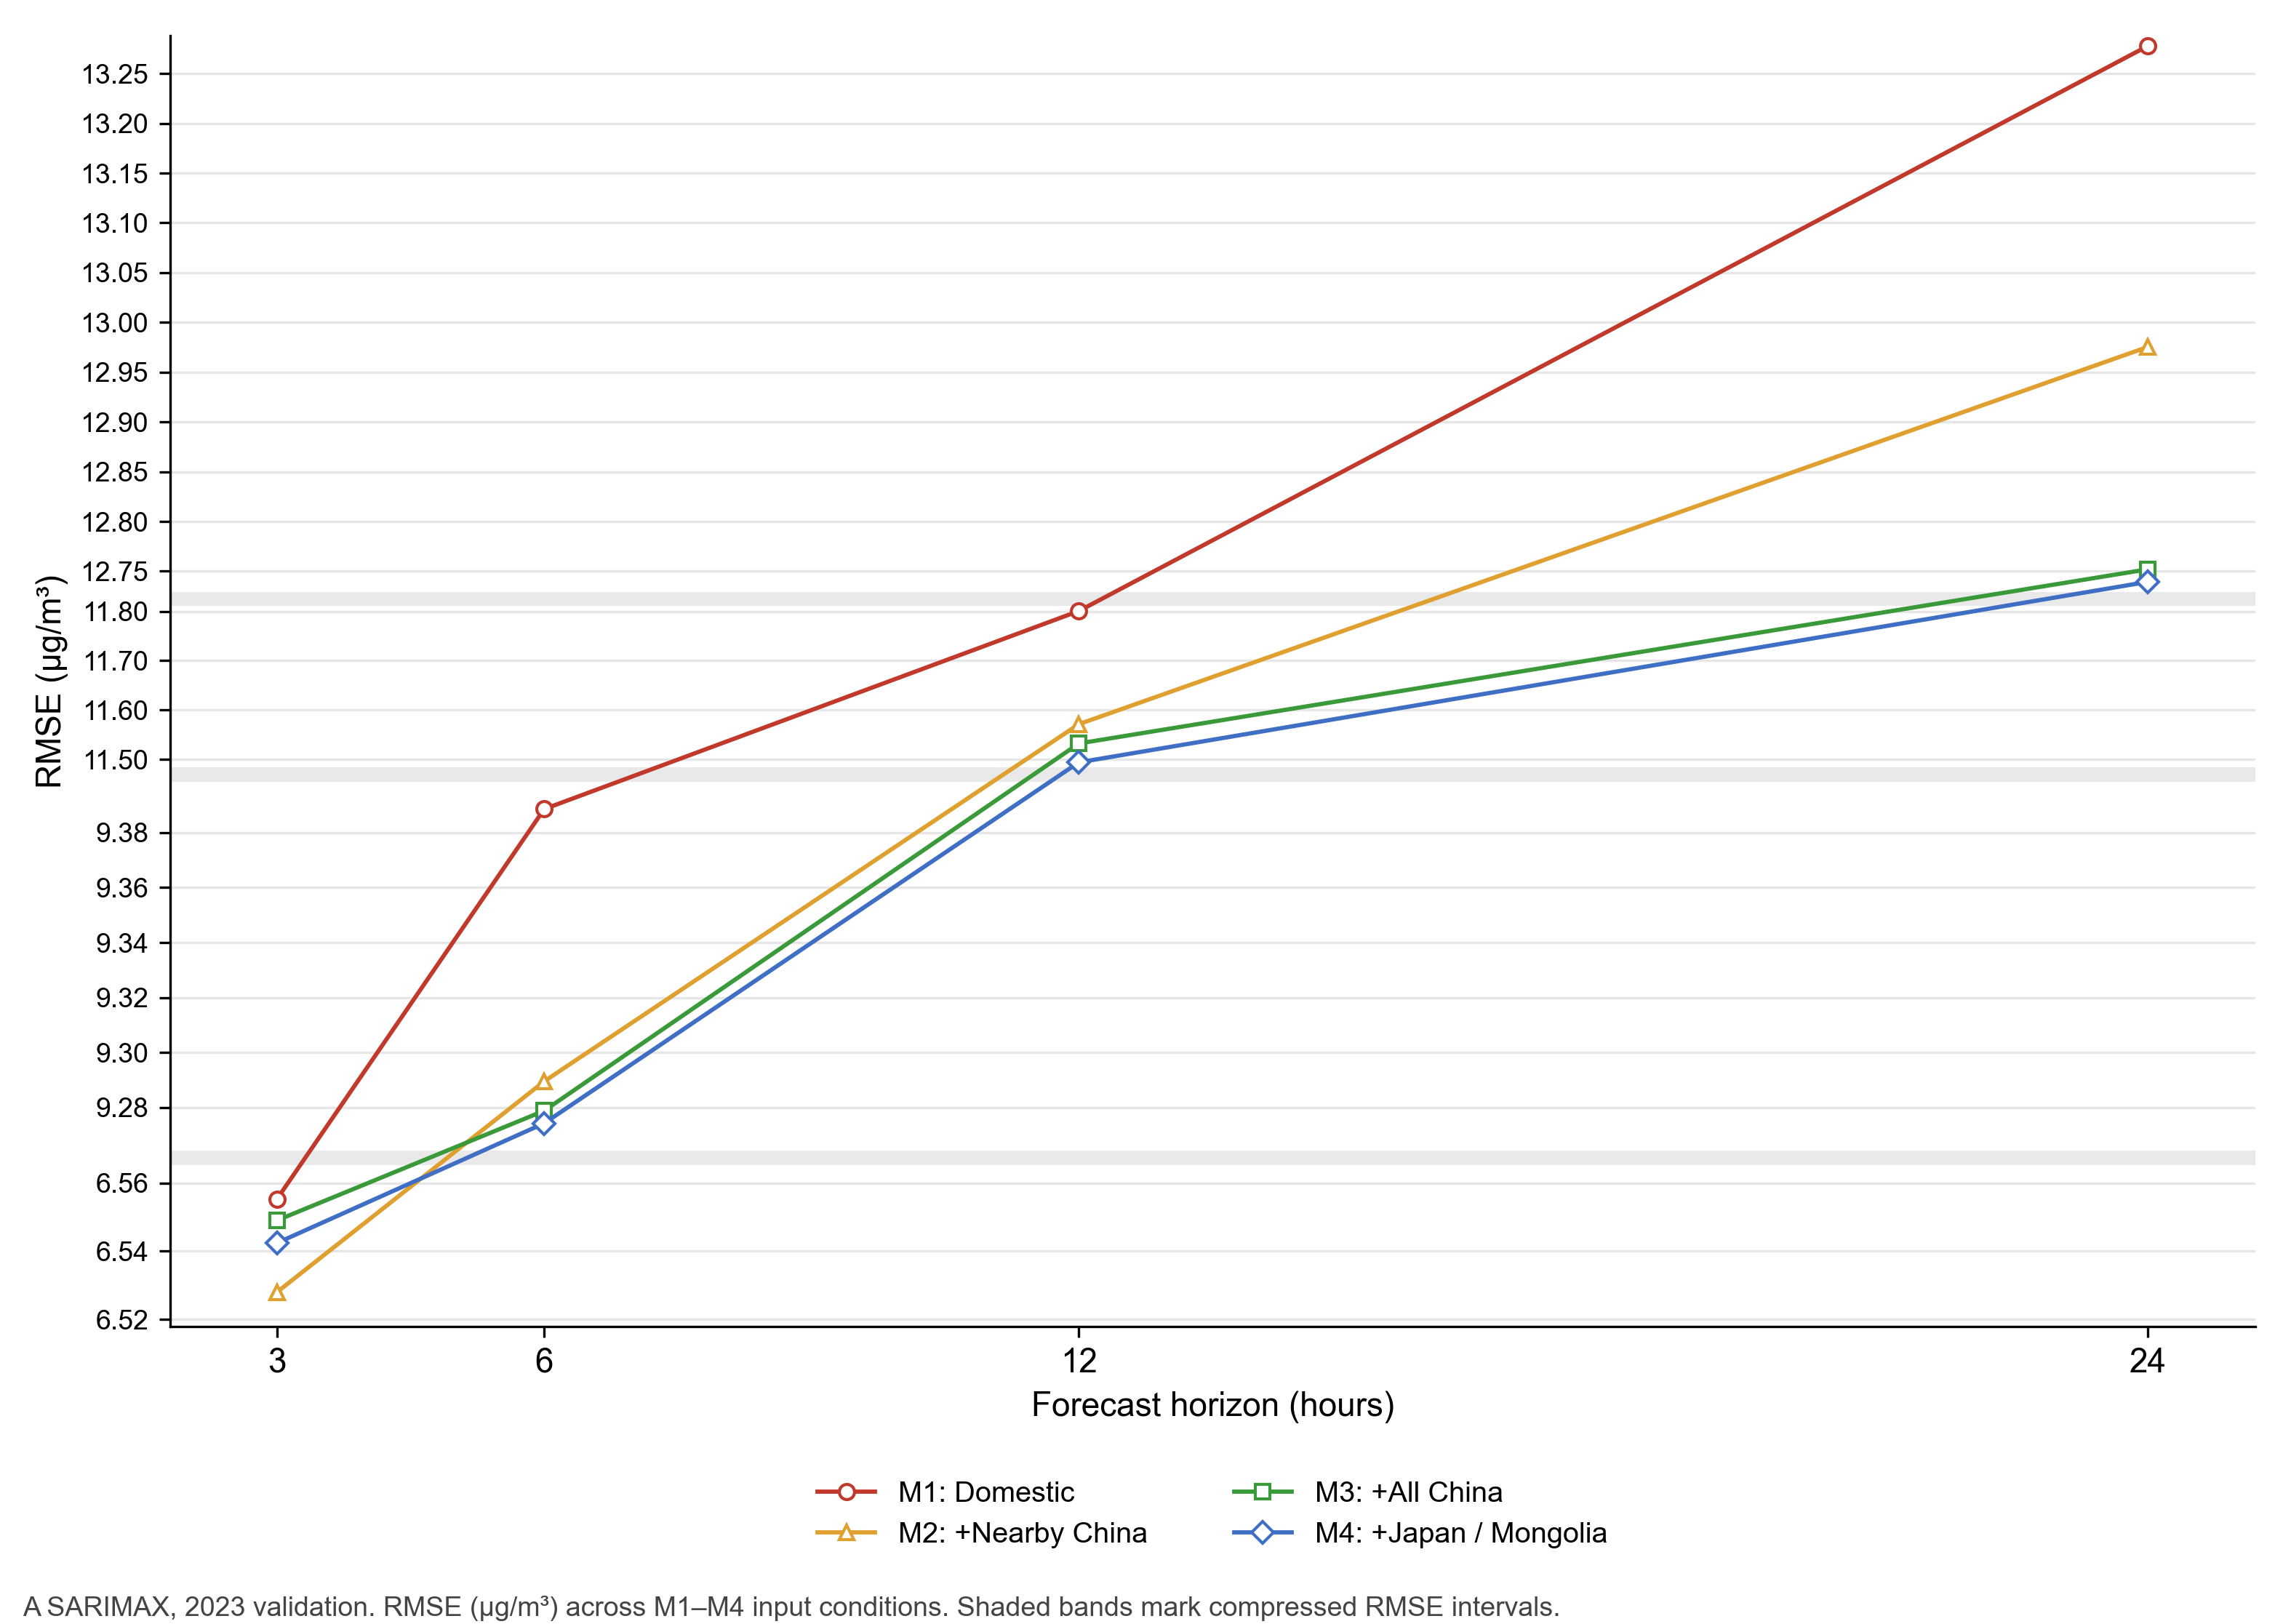

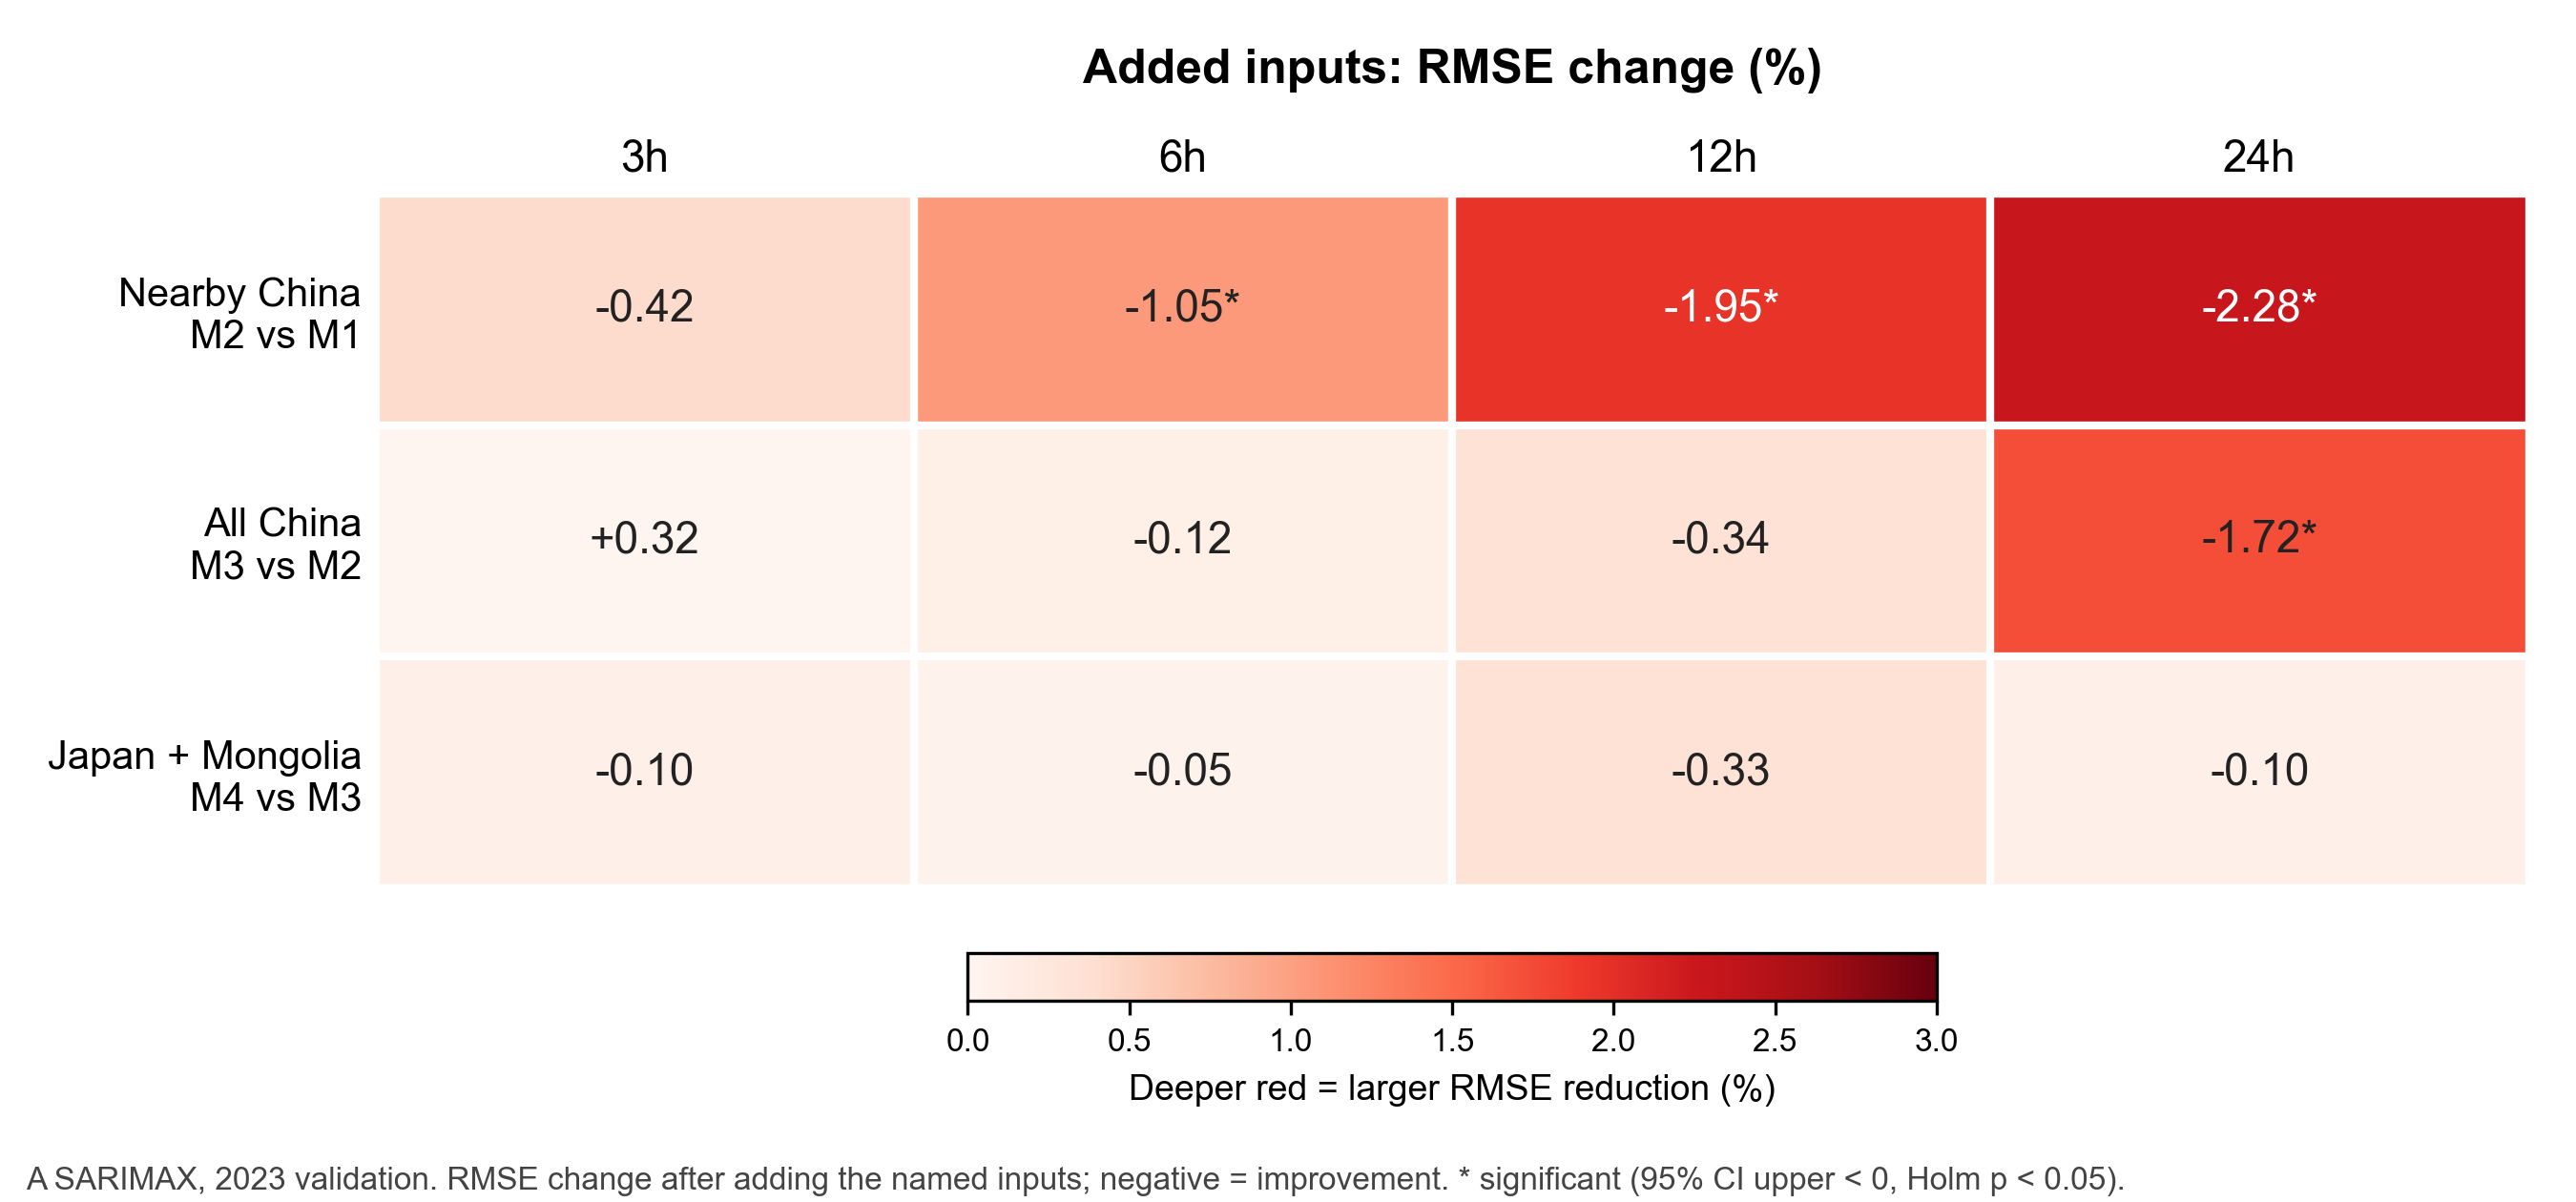

In [19]:
from IPython.display import Image, display
run('make_fig_M.py')
run('make_fig_M_heat.py')
display(Image('figures_en/fig_A_M1_M4_rmse.png', width=900))
display(Image('figures_en/fig_A_M_added_inputs.png', width=900))